# Exercise 4 — E-Commerce Text & Quantitative Analytics
## Dataset
The supplied Kaggle file `Dataset-SA.csv` is included in this folder.

Its columns are `product_name`, `product_price`, `Rate`, `Review`, `Summary`, and `Sentiment`. The exercise requires product-level mean rating and mean price, plus a Word Cloud from `Summary`.

## Cleaning approach
- Convert `Rate` and `product_price` to numeric values.
- Invalid values are converted to `NaN` and excluded from the aggregation.
- Remove rows with missing product name, rating or price.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from wordcloud import WordCloud, STOPWORDS

PROJECT_DIR = Path(r"C:\Users\fmsch\assignment")
DATA_DIR = PROJECT_DIR / "Exercise4_DhruvRawat"
DATA_DIR.mkdir(parents=True, exist_ok=True)
DATA_FILE = DATA_DIR / "Dataset-SA.csv"

df = pd.read_csv(DATA_FILE)
print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())

Dataset shape: (205052, 6)
Columns: ['product_name', 'product_price', 'Rate', 'Review', 'Summary', 'Sentiment']


,product_name,product_price,Rate,Review,Summary,Sentiment
0,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,5,super!,great cooler excellent air flow and for this p...,positive
1,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,5,awesome,best budget 2 fit cooler nice cooling,positive
2,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,3,fair,the quality is good but the power of air is de...,positive
3,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,1,useless product,very bad product its a only a fan,negative
4,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,3,fair,ok ok product,neutral


In [2]:
# Clean the rating and price columns.
df["Rate"] = pd.to_numeric(df["Rate"], errors="coerce")

df["product_price"] = (
    df["product_price"].astype(str)
    .str.replace(",", "", regex=False)
    .str.replace(r"[^0-9.\\-]", "", regex=True)
)
df["product_price"] = pd.to_numeric(df["product_price"], errors="coerce")

clean_df = df.dropna(subset=["product_name", "Rate", "product_price"]).copy()
clean_df["product_name"] = clean_df["product_name"].astype(str).str.strip()
clean_df = clean_df[clean_df["product_name"].ne("")]

print("Rows loaded:", len(df))
print("Rows retained after cleaning:", len(clean_df))
print("Rows excluded:", len(df) - len(clean_df))
display(clean_df[["product_name", "Rate", "product_price"]].head())

Rows loaded: 205052
Rows retained after cleaning: 205049
Rows excluded: 3


,product_name,Rate,product_price
0,Candes 12 L Room/Personal Air Cooler??????(Whi...,5.0,3999
1,Candes 12 L Room/Personal Air Cooler??????(Whi...,5.0,3999
2,Candes 12 L Room/Personal Air Cooler??????(Whi...,3.0,3999
3,Candes 12 L Room/Personal Air Cooler??????(Whi...,1.0,3999
4,Candes 12 L Room/Personal Air Cooler??????(Whi...,3.0,3999


In [3]:
# Group by product name and calculate mean rating and mean price.
items = (
    clean_df.groupby("product_name", as_index=False)
    .agg(
        mean_rating=("Rate", "mean"),
        mean_price=("product_price", "mean"),
        review_count=("Rate", "count")
    )
    .sort_values(["mean_rating", "review_count"], ascending=[False, False])
)

display(items.head(20))

excel_path = DATA_DIR / "Exercise4_Product_Summary.xlsx"
items.to_excel(excel_path, index=False)
print("Product summary exported to:", excel_path.resolve())

,product_name,mean_rating,mean_price,review_count
85,BAJAJ FX7 600 W Food Processor,5.000000,6390.000000,10
909,ZunVolt Power MG5 500 Mixer Grinder 3 Jars White,5.000000,1290.000000,10
408,LA VERNE Self Design Double Mink Blanket for ...,5.000000,549.000000,5
772,Stylish Brown Sports Men Watches Multifunction...,5.000000,404.000000,5
842,VH000008C Analog Watch - For Women,5.000000,1649.000000,4
843,VH000008D Analog Watch - For Women,5.000000,1649.000000,4
420,LS2917 Mesh Strap All Black Avatar Day and Dat...,5.000000,299.000000,2
440,Lopezs Microfiber Floor MatGrey23mm Medium,4.952381,229.000000,21
228,Educart CBSE Class 10 Sample Papers 202223 Bun...,4.937500,482.000000,16
194,DOJI 6 watt colorWarmWhitespot lightfocus ligh...,4.900000,599.000000,10


Product summary exported to: C:\Users\fmsch\assignment\Exercise4_DhruvRawat\Exercise4_Product_Summary.xlsx


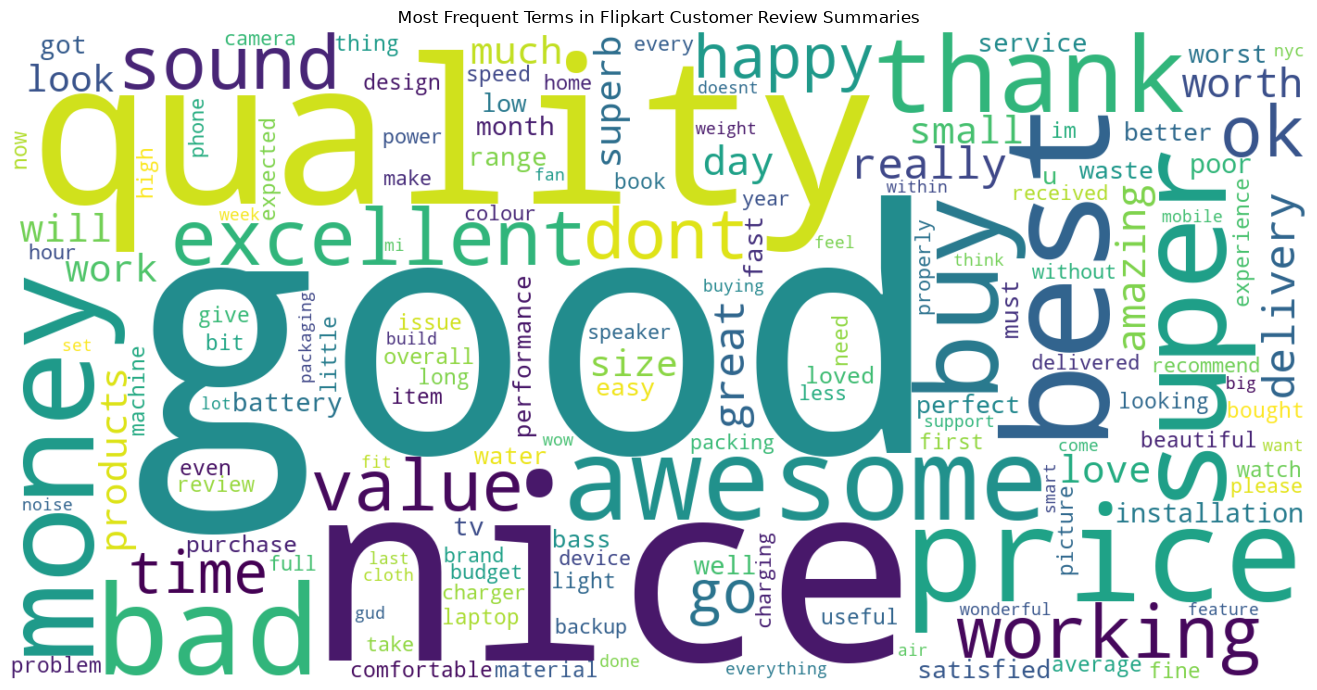

In [4]:
# Generate a Word Cloud from the Summary column.
review_summaries = clean_df["Summary"].dropna().astype(str)
all_text = " ".join(review_summaries.tolist())

if not all_text.strip():
    raise ValueError("No usable text was found in the Summary column.")

custom_stopwords = set(STOPWORDS) | {
    "product", "flipkart", "one", "also", "use", "used", "using"
}

wordcloud = WordCloud(
    width=1400,
    height=700,
    background_color="white",
    stopwords=custom_stopwords,
    collocations=False,
    max_words=150
).generate(all_text)

plt.figure(figsize=(14, 7))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Most Frequent Terms in Flipkart Customer Review Summaries")
plt.tight_layout()
plt.savefig(DATA_DIR / "Exercise4_WordCloud.png", dpi=180, bbox_inches="tight")
plt.show()